In [41]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [42]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [43]:
# Define the MPA model characteristics, Transmitter and Receiver size and position
# and the waveform to be used. 
times = torch.logspace(-5, -3, 32)
fwrTD = Forward.mpa(tx, rx, times, filterfunc=recfilter)


frqs = torch.logspace(3,6,51)
fwrFD = ForwardFD.mpa(tx, rx, frqs, filterfunc=recfilter)

In [44]:
# Define the model parameters fopr the MPA model. 


second_layer_rhos = torch.tensor([500, 100, 50, 10], dtype=torch.double)

thickness = torch.tensor([30], dtype=torch.double)

# Ip values for the MPA model in the second layer
phi_max_values = torch.logspace(start=torch.log10(torch.tensor(1)), 
                            end=torch.log10(torch.tensor(1000.0)), 
                            steps=10, dtype=torch.double)/1e3

tau_phi_values = torch.logspace(start=torch.log10(torch.tensor(1e-5)),
                            end=torch.log10(torch.tensor(1e-2)), 
                            steps=10, dtype=torch.double)

c_values = torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], dtype=torch.double)

phi_2 = torch.tensor(0.001, dtype=torch.double)
tau_phi_2 = 1e-4
c_2 = 0.5


# Colormap
cmap = cm.get_cmap('rainbow')
norm = mcolors.Normalize(vmin=float(c_values.min()), vmax=float(c_values.max()))
sm = cm.ScalarMappable(cmap=cmap, norm=norm)



C:\Users\au653994\AppData\Local\Temp\ipykernel_7260\4127513877.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


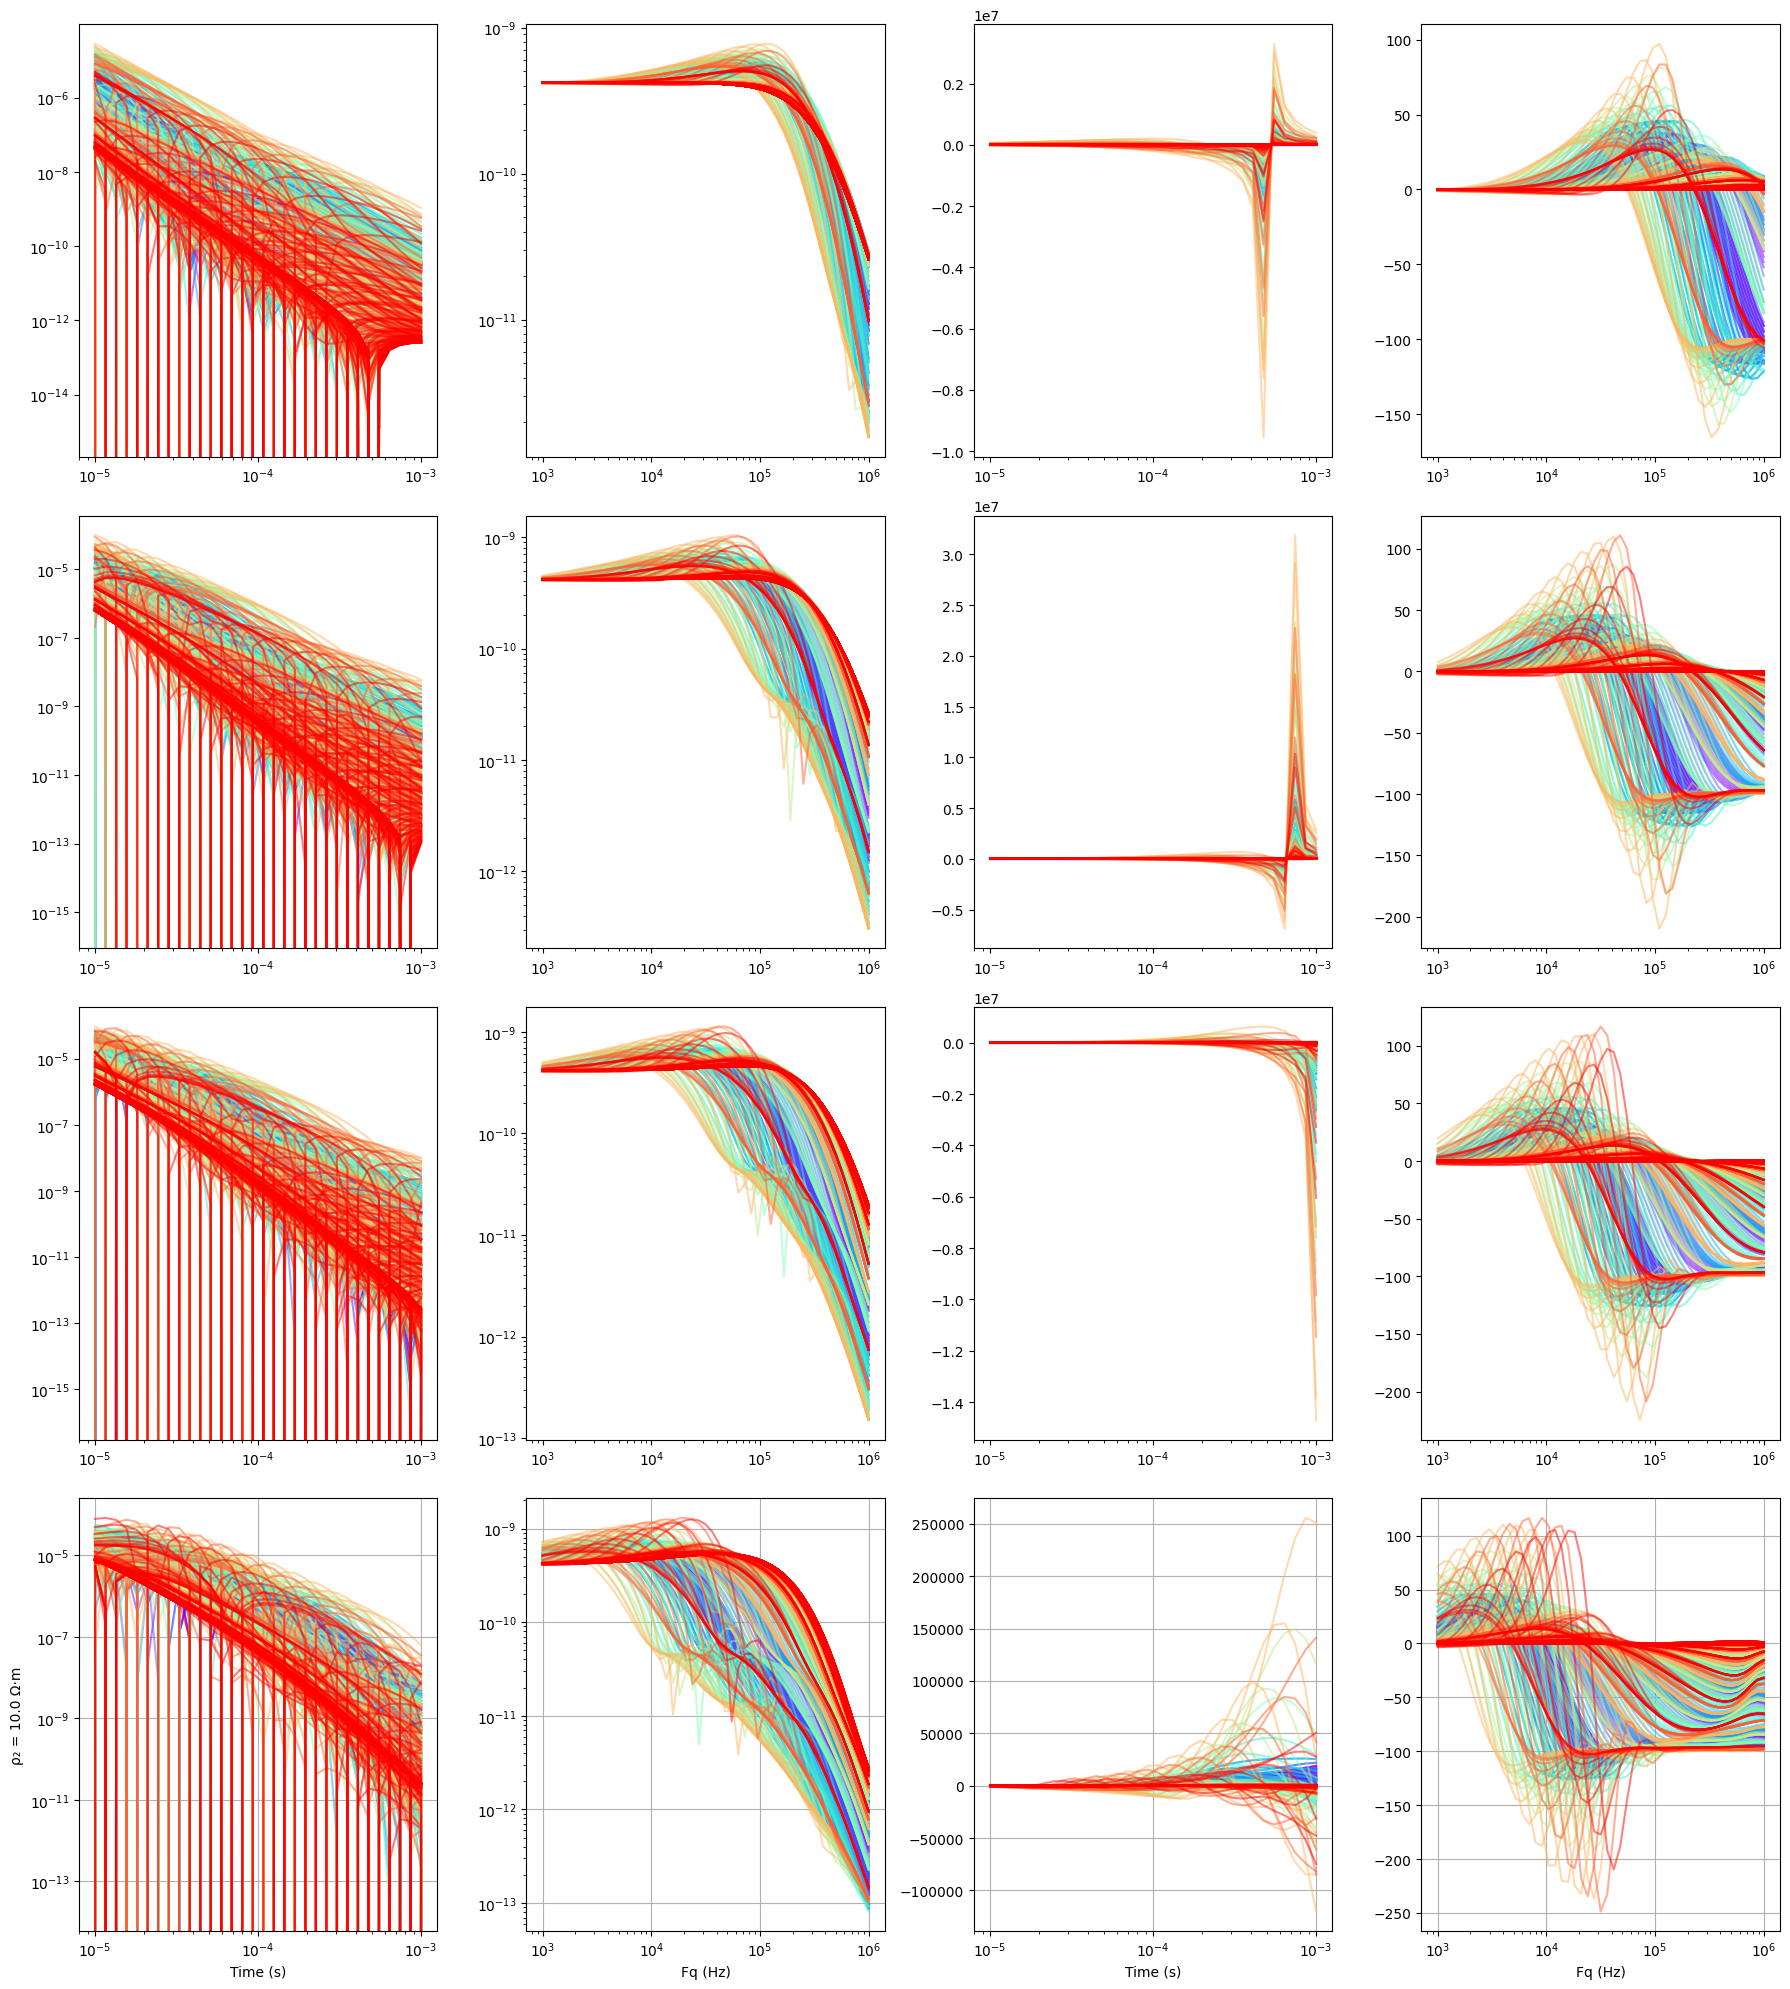

In [45]:
n_models = len(second_layer_rhos)

fig,axs = plt.subplots(n_models, 4, figsize=(18, 5*n_models))

for i, rho2 in enumerate(second_layer_rhos):
    #rho = torch.tensor([10, rho2.item()], dtype=torch.double)
    rho = torch.tensor([rho2.item(), 1000], dtype=torch.double)
    
    # Reference model to compute all the % changes
    #rho_ref = torch.tensor([10, rho2.item()], dtype=torch.double)
    rho_ref = torch.tensor([rho2.item(), 1000], dtype=torch.double)
    phi_ref = torch.tensor([phi_max_values[0].item(), phi_2], dtype=torch.double)
    tau_phi_ref = torch.tensor([tau_phi_values[0].item(), tau_phi_2], dtype=torch.double)
    c_ref = torch.tensor([c_values[0].item(), c_2], dtype=torch.double)

    # Compute the refence forward model
    dbdt_ref = fwrTD(rho_ref, phi_ref, tau_phi_ref, c_ref, thickness)
    dbdf_ref = fwrFD(rho_ref, phi_ref, tau_phi_ref, c_ref, thickness)


    for c0 in c_values:
        color = cmap(norm(c0.item()))

        for phi0 in phi_max_values:
            for tau0 in tau_phi_values:
                phi_max = torch.tensor([phi0.item(), phi_2.item()], dtype=torch.double)
                tau_phi = torch.tensor([tau0.item(), tau_phi_2], dtype=torch.double)
                c = torch.tensor([c0.item(), c_2], dtype=torch.double)

                # Compute the model response for the MPA model
                dbdt = fwrTD(rho, phi_max, tau_phi, c, thickness)
                dbdf = fwrFD(rho, phi_max, tau_phi, c, thickness)

                # Plot the results
                axs[i][0].loglog(times, dbdt, color=color, linestyle='-', alpha=0.5)
                axs[i][0].loglog(times, -dbdt, color=color, linestyle='-', alpha=0.5)
                axs[i][1].loglog(frqs, torch.abs(dbdf), color=color, linestyle='-', alpha=0.5)

                # Percentage change plots
                pct_change_dbdt = ((dbdt - dbdt_ref) / dbdt_ref) * 100
                pct_change_dbdf = ((dbdf - dbdf_ref) / dbdf_ref) * 100

                axs[i][2].semilogx(times, pct_change_dbdt, color=color, alpha=0.5)
                axs[i][3].semilogx(frqs, pct_change_dbdf, color=color, alpha=0.5)

if i==0:
    # Add a colorbar for the first row
    axs[i][0].set_title("T-domain (dB/dt)")
    axs[i][1].set_title("F-domain (dB/df)")
    axs[i][2].set_title("% Change T-domain")
    axs[i][3].set_title("% Change F-domain")

for j in range(4):
    axs[i][j].set_xlabel('Time (s)' if j in [0,2] else 'Fq (Hz)')
    axs[i][j].grid(True)

    axs[i][0].set_ylabel(f'ρ₂ = {rho2.item()} Ω·m')



savefig = True

plt.tight_layout()
#plt.colorbar(sm, ax=axs[:, -1], label='C value', orientation='vertical')

if savefig:
    plt.savefig(r'c:\Users\au653994\OneDrive - Aarhus universitet\Documents\PhD\anemone\Figures\2L_IP_Var\MPA_L2_1000ohm.png', dpi=300, bbox_inches='tight')